#### Plot figures for heat wave detection

In [ ]:
# === load modules ===
import numpy as np
import h5py
from pathlib import Path
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import netCDF4 as nc
import pickle

In [ ]:
# === config filepaths ===
DATA_DIR = Path("Data/")
ERA5_DIR = Path("Data/ERA5/")

lat_global = np.arange(90, -90-0.25, -0.25)
lon_global = np.arange(-180, 180, 0.25)

Ny, Nx = len(lat_global), len(lon_global)

years = range(2020, 2026)

# --- choose bias correction method 
METHODS = ["CDFt", "ECBC", "R2D2", "MBCn", "TSMBC"]

In [3]:
# load the ERA5 land-sea mask
def load_landmask(fname):
    """Return (lat, lon, land_sea_mask) or None if not available"""
    if fname is None or not fname.exists():
        return None
    with nc.Dataset(fname, "r") as ds:
        lat = ds.variables["latitude"][:]
        lon = ds.variables["longitude"][:]
        # land binary mask: 0-ocean; 1-land
        lsm = ds.variables["lsm"][0,:,:]
    return (np.array(lat), np.array(lon), np.array(lsm))

LSMASK = load_landmask(fname=ERA5_DIR/"ERA5reanalysis_landseamask.nc")
lat_era, lon_era0, lsm_era0 = LSMASK

# now convert land-sea mask from lon: 0-360 to lon: -180-180
idlon1 = np.where((lon_era0>=0)&(lon_era0<180))[0]
idlon2 = np.where((lon_era0>=180)&(lon_era0<360))[0]
lon_era = np.concatenate((lon_era0[idlon2]-360.0, lon_era0[idlon1]), axis=0)
# 0-ocean; 1-land
lsm_era = np.concatenate((lsm_era0[:, idlon2], lsm_era0[:, idlon1]), axis=1)
# determine the land-sea mask: True (1) for land / False (0) for sea
lsmask_era = (lsm_era >= 0.5)

#### Post-process and plot manuscript figures

In [ ]:
def load_and_score_heatwave(type_heat, lead_day, years, data_dir):

    with open(f"{data_dir}/CREDIT_heatwave_type{type_heat}_lead{lead_day:02d}.pkl", "rb") as f:
        results = pickle.load(f)

    # accumulators
    totals = {
        "hwdays_obs": 0, "hwdays_og": 0, "hwdays_bc": 0,
        "heat_obs": 0, "heat_og": 0, "heat_bc": 0,
        "TP_og": 0, "FP_og": 0, "TN_og": 0, "FN_og": 0,
        "TP_corr": 0, "FP_corr": 0, "TN_corr": 0, "FN_corr": 0,
    }

    for iyear in years:
        totals["hwdays_obs"] += results["metrics_obs"][iyear]["hw_days"]
        totals["hwdays_og"]  += results["metrics_og"][iyear]["hw_days"]
        totals["hwdays_bc"]  += results["metrics_corr"][iyear]["hw_days"]

        totals["heat_obs"] += results["metrics_obs"][iyear]["cum_heat"]
        totals["heat_og"]  += results["metrics_og"][iyear]["cum_heat"]
        totals["heat_bc"]  += results["metrics_corr"][iyear]["cum_heat"]

        for k in ["TP_og", "FP_og", "TN_og", "FN_og",
                  "TP_corr", "FP_corr", "TN_corr", "FN_corr"]:
            totals[k] += results[k][iyear]

    # skill scores
    eps = 1e-9
    def scores(TP, FP, FN):
        POD = TP / (TP + FN + eps)
        SR  = 1 - (FP / (TP + FP + eps))
        CSI = TP / (TP + FN + FP + eps)
        return POD, SR, CSI

    totals["POD_og"], totals["SR_og"], totals["CSI_og"] = scores(
        totals["TP_og"], totals["FP_og"], totals["FN_og"])
    totals["POD_corr"], totals["SR_corr"], totals["CSI_corr"] = scores(
        totals["TP_corr"], totals["FP_corr"], totals["FN_corr"])

    return totals


# --- run for all three heatwave types ---
lead_day = 1

heatwave_types = ["day", "night", "comp"]
all_results = {}

for t in heatwave_types:
    all_results[t] = load_and_score_heatwave(t, lead_day, years, DATA_DIR)

##### Plot the heat wave occurrence CSI figure

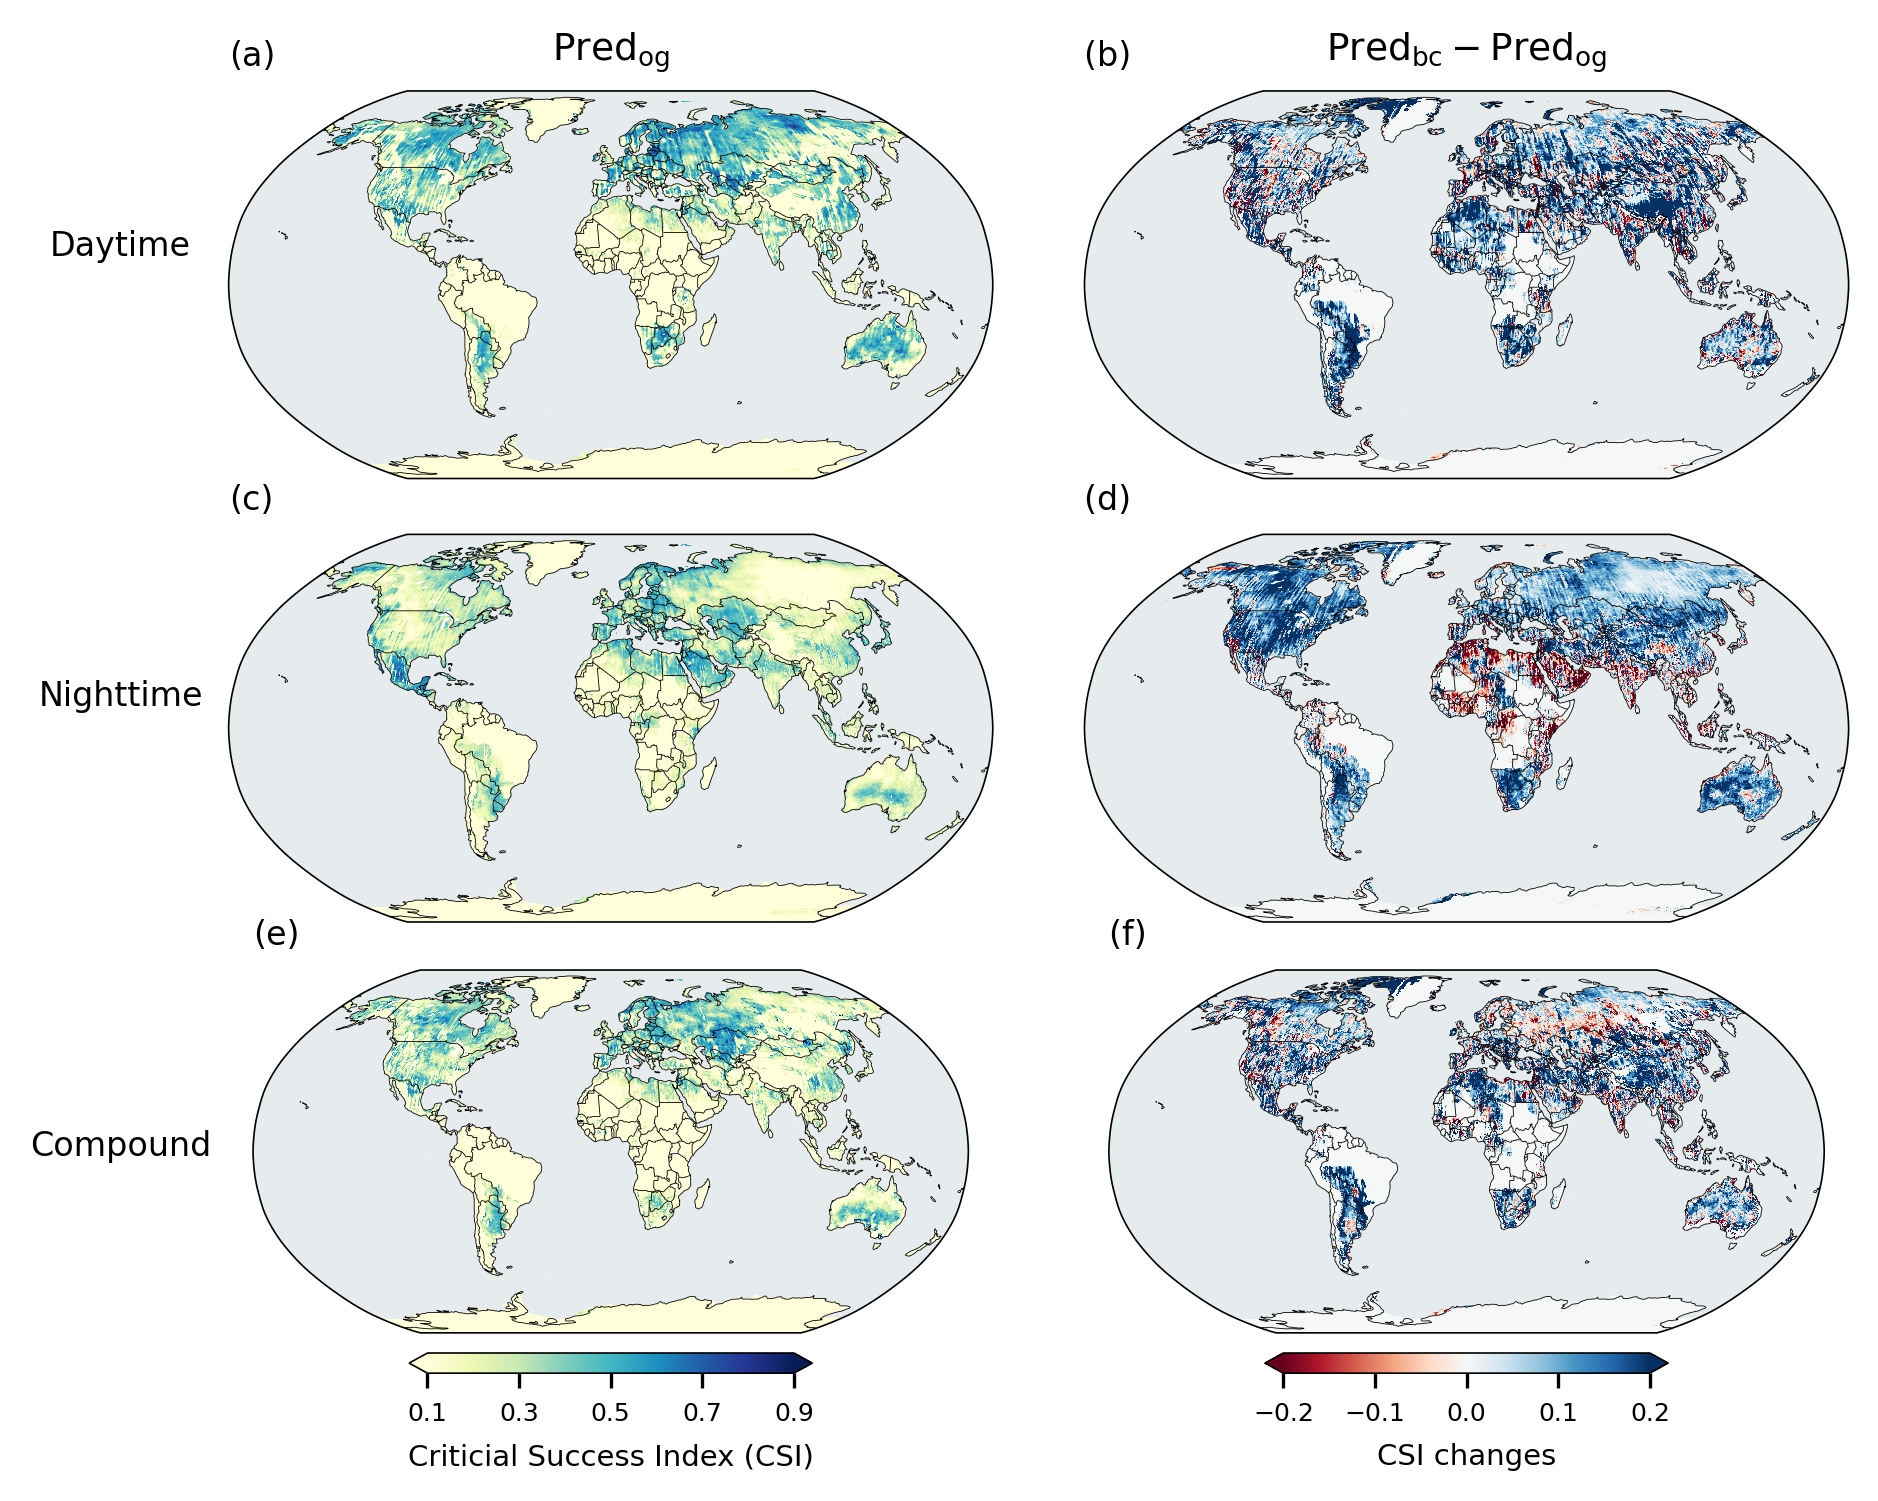

In [7]:
# plot the manuscript figure of heatwave frequency CSI comparison
CSI_day_og = np.where(lsmask_era, all_results["day"]["CSI_og"], np.nan)
CSI_day_corr = np.where(lsmask_era, all_results["day"]["CSI_corr"], np.nan)
CSI_night_og = np.where(lsmask_era, all_results["night"]["CSI_og"], np.nan)
CSI_night_corr = np.where(lsmask_era, all_results["night"]["CSI_corr"], np.nan)
CSI_comp_og = np.where(lsmask_era, all_results["comp"]["CSI_og"], np.nan)
CSI_comp_corr = np.where(lsmask_era, all_results["comp"]["CSI_corr"], np.nan)

lon2d, lat2d = np.meshgrid(lon_era, lat_era)


fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(6, 5), dpi=300, 
                         constrained_layout=False, subplot_kw={'projection': ccrs.Robinson()})
plt.subplots_adjust(left=0.08, right=0.98, top=0.92, bottom=0.06, wspace=0.12, hspace=0.1)

ocean =  cfeature.OCEAN.with_scale("110m")

# add super titles
fig.text(0.02, 0.8, "Daytime", ha="center", va="bottom", fontsize=8)
fig.text(0.02, 0.5, "Nighttime", ha="center", va="bottom", fontsize=8)
fig.text(0.02, 0.2, "Compound", ha="center", va="bottom", fontsize=8)

axes[0,0].text(0.5, 1.1, r"$\mathrm{Pred}_{\mathrm{og}}$", transform=axes[0,0].transAxes,
                rotation=0, ha="center", va="center", fontsize=9,)
axes[0,1].text(0.5, 1.1, r"$\mathrm{Pred}_{\mathrm{bc}}-\mathrm{Pred}_{\mathrm{og}}$", transform=axes[0,1].transAxes,
                rotation=0, ha="center", va="center", fontsize=9,)

for ax in axes[0,:]:
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

for ax in axes[1,:]:
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

for ax in axes[2,:]:
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

axes[0,0].set_title("(a)", loc='left', fontsize=8, fontweight='normal')
axes[0,0].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im1 = axes[0,0].pcolormesh(lon2d, lat2d, CSI_day_og, cmap='YlGnBu', shading='auto', vmin=0.1, vmax=0.9, transform=ccrs.PlateCarree())
axes[0,0].coastlines(linewidth=0.2)
axes[0,0].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[0,1].set_title("(b) ", loc='left', fontsize=8, fontweight='normal')
axes[0,1].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im2 = axes[0,1].pcolormesh(lon2d, lat2d, CSI_day_corr - CSI_day_og, cmap='RdBu', shading='auto', vmin=-0.2, vmax=0.2, transform=ccrs.PlateCarree())
axes[0,1].coastlines(linewidth=0.2)
axes[0,1].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[1,0].set_title("(c)", loc='left', fontsize=8, fontweight='normal')
axes[1,0].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im3 = axes[1,0].pcolormesh(lon2d, lat2d, CSI_night_og, cmap='YlGnBu', shading='auto', vmin=0.1, vmax=0.9, transform=ccrs.PlateCarree())
axes[1,0].coastlines(linewidth=0.2)
axes[1,0].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[1,1].set_title("(d) ", loc='left', fontsize=8, fontweight='normal')
axes[1,1].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im4 = axes[1,1].pcolormesh(lon2d, lat2d, CSI_night_corr - CSI_night_og, cmap='RdBu', shading='auto', vmin=-0.2, vmax=0.2, transform=ccrs.PlateCarree())
axes[1,1].coastlines(linewidth=0.2)
axes[1,1].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[2,0].set_title("(e)", loc='left', fontsize=8, fontweight='normal')
axes[2,0].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im5 = axes[2,0].pcolormesh(lon2d, lat2d, CSI_comp_og, cmap='YlGnBu', shading='auto', vmin=0.1, vmax=0.9, transform=ccrs.PlateCarree())
axes[2,0].coastlines(linewidth=0.2)
axes[2,0].add_feature(cfeature.BORDERS, linewidth=0.2)
cbar1 = plt.colorbar(im5, ax=axes[2,0], fraction=0.05, shrink=0.75, extend='both', pad=0.05, ticks=np.arange(0.1, 1.0, 0.2), orientation="horizontal")
cbar1.ax.tick_params(labelsize=6)
cbar1.set_label('Criticial Success Index (CSI)', fontsize=7)
cbar1.outline.set_linewidth(0.4)

axes[2,1].set_title("(f) ", loc='left', fontsize=8, fontweight='normal')
axes[2,1].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im6 = axes[2,1].pcolormesh(lon2d, lat2d, CSI_comp_corr - CSI_comp_og, cmap='RdBu', shading='auto', vmin=-0.2, vmax=0.2, transform=ccrs.PlateCarree())
axes[2,1].coastlines(linewidth=0.2)
axes[2,1].add_feature(cfeature.BORDERS, linewidth=0.2)
cbar2 = plt.colorbar(im6, ax=axes[2,1], fraction=0.05, shrink=0.75, extend='both', pad=0.05, ticks=np.arange(-0.2, 0.3, 0.1), orientation="horizontal")
cbar2.ax.tick_params(labelsize=6)
cbar2.set_label('CSI changes', fontsize=7)
cbar2.outline.set_linewidth(0.4)


##### Plot the heat wave intensity comparison figure

In [7]:
heatave_day_og = np.where(lsmask_era, all_results["day"]["heat_og"]/all_results["day"]["hwdays_og"], np.nan)
heatave_day_obs = np.where(lsmask_era, all_results["day"]["heat_obs"]/all_results["day"]["hwdays_obs"], np.nan)
heatave_day_bc = np.where(lsmask_era, all_results["day"]["heat_bc"]/all_results["day"]["hwdays_bc"], np.nan)

heatave_night_og = np.where(lsmask_era, all_results["night"]["heat_og"]/all_results["night"]["hwdays_og"], np.nan)
heatave_night_obs = np.where(lsmask_era, all_results["night"]["heat_obs"]/all_results["night"]["hwdays_obs"], np.nan)
heatave_night_bc = np.where(lsmask_era, all_results["night"]["heat_bc"]/all_results["night"]["hwdays_bc"], np.nan)

heatave_comp_og = np.where(lsmask_era, all_results["comp"]["heat_og"]/all_results["comp"]["hwdays_og"], np.nan)
heatave_comp_obs = np.where(lsmask_era, all_results["comp"]["heat_obs"]/all_results["comp"]["hwdays_obs"], np.nan)
heatave_comp_bc = np.where(lsmask_era, all_results["comp"]["heat_bc"]/all_results["comp"]["hwdays_bc"], np.nan)

/scratch/yxie/tmp/ipykernel_3333780/1022802153.py:1: RuntimeWarning: invalid value encountered in divide
  heatave_day_og = np.where(lsmask_era, all_results["day"]["heat_og"]/all_results["day"]["hwdays_og"], np.nan)
/scratch/yxie/tmp/ipykernel_3333780/1022802153.py:2: RuntimeWarning: invalid value encountered in divide
  heatave_day_obs = np.where(lsmask_era, all_results["day"]["heat_obs"]/all_results["day"]["hwdays_obs"], np.nan)
/scratch/yxie/tmp/ipykernel_3333780/1022802153.py:3: RuntimeWarning: invalid value encountered in divide
  heatave_day_bc = np.where(lsmask_era, all_results["day"]["heat_bc"]/all_results["day"]["hwdays_bc"], np.nan)
/scratch/yxie/tmp/ipykernel_3333780/1022802153.py:5: RuntimeWarning: invalid value encountered in divide
  heatave_night_og = np.where(lsmask_era, all_results["night"]["heat_og"]/all_results["night"]["hwdays_og"], np.nan)
/scratch/yxie/tmp/ipykernel_3333780/1022802153.py:6: RuntimeWarning: invalid value encountered in divide
  heatave_night_obs = 

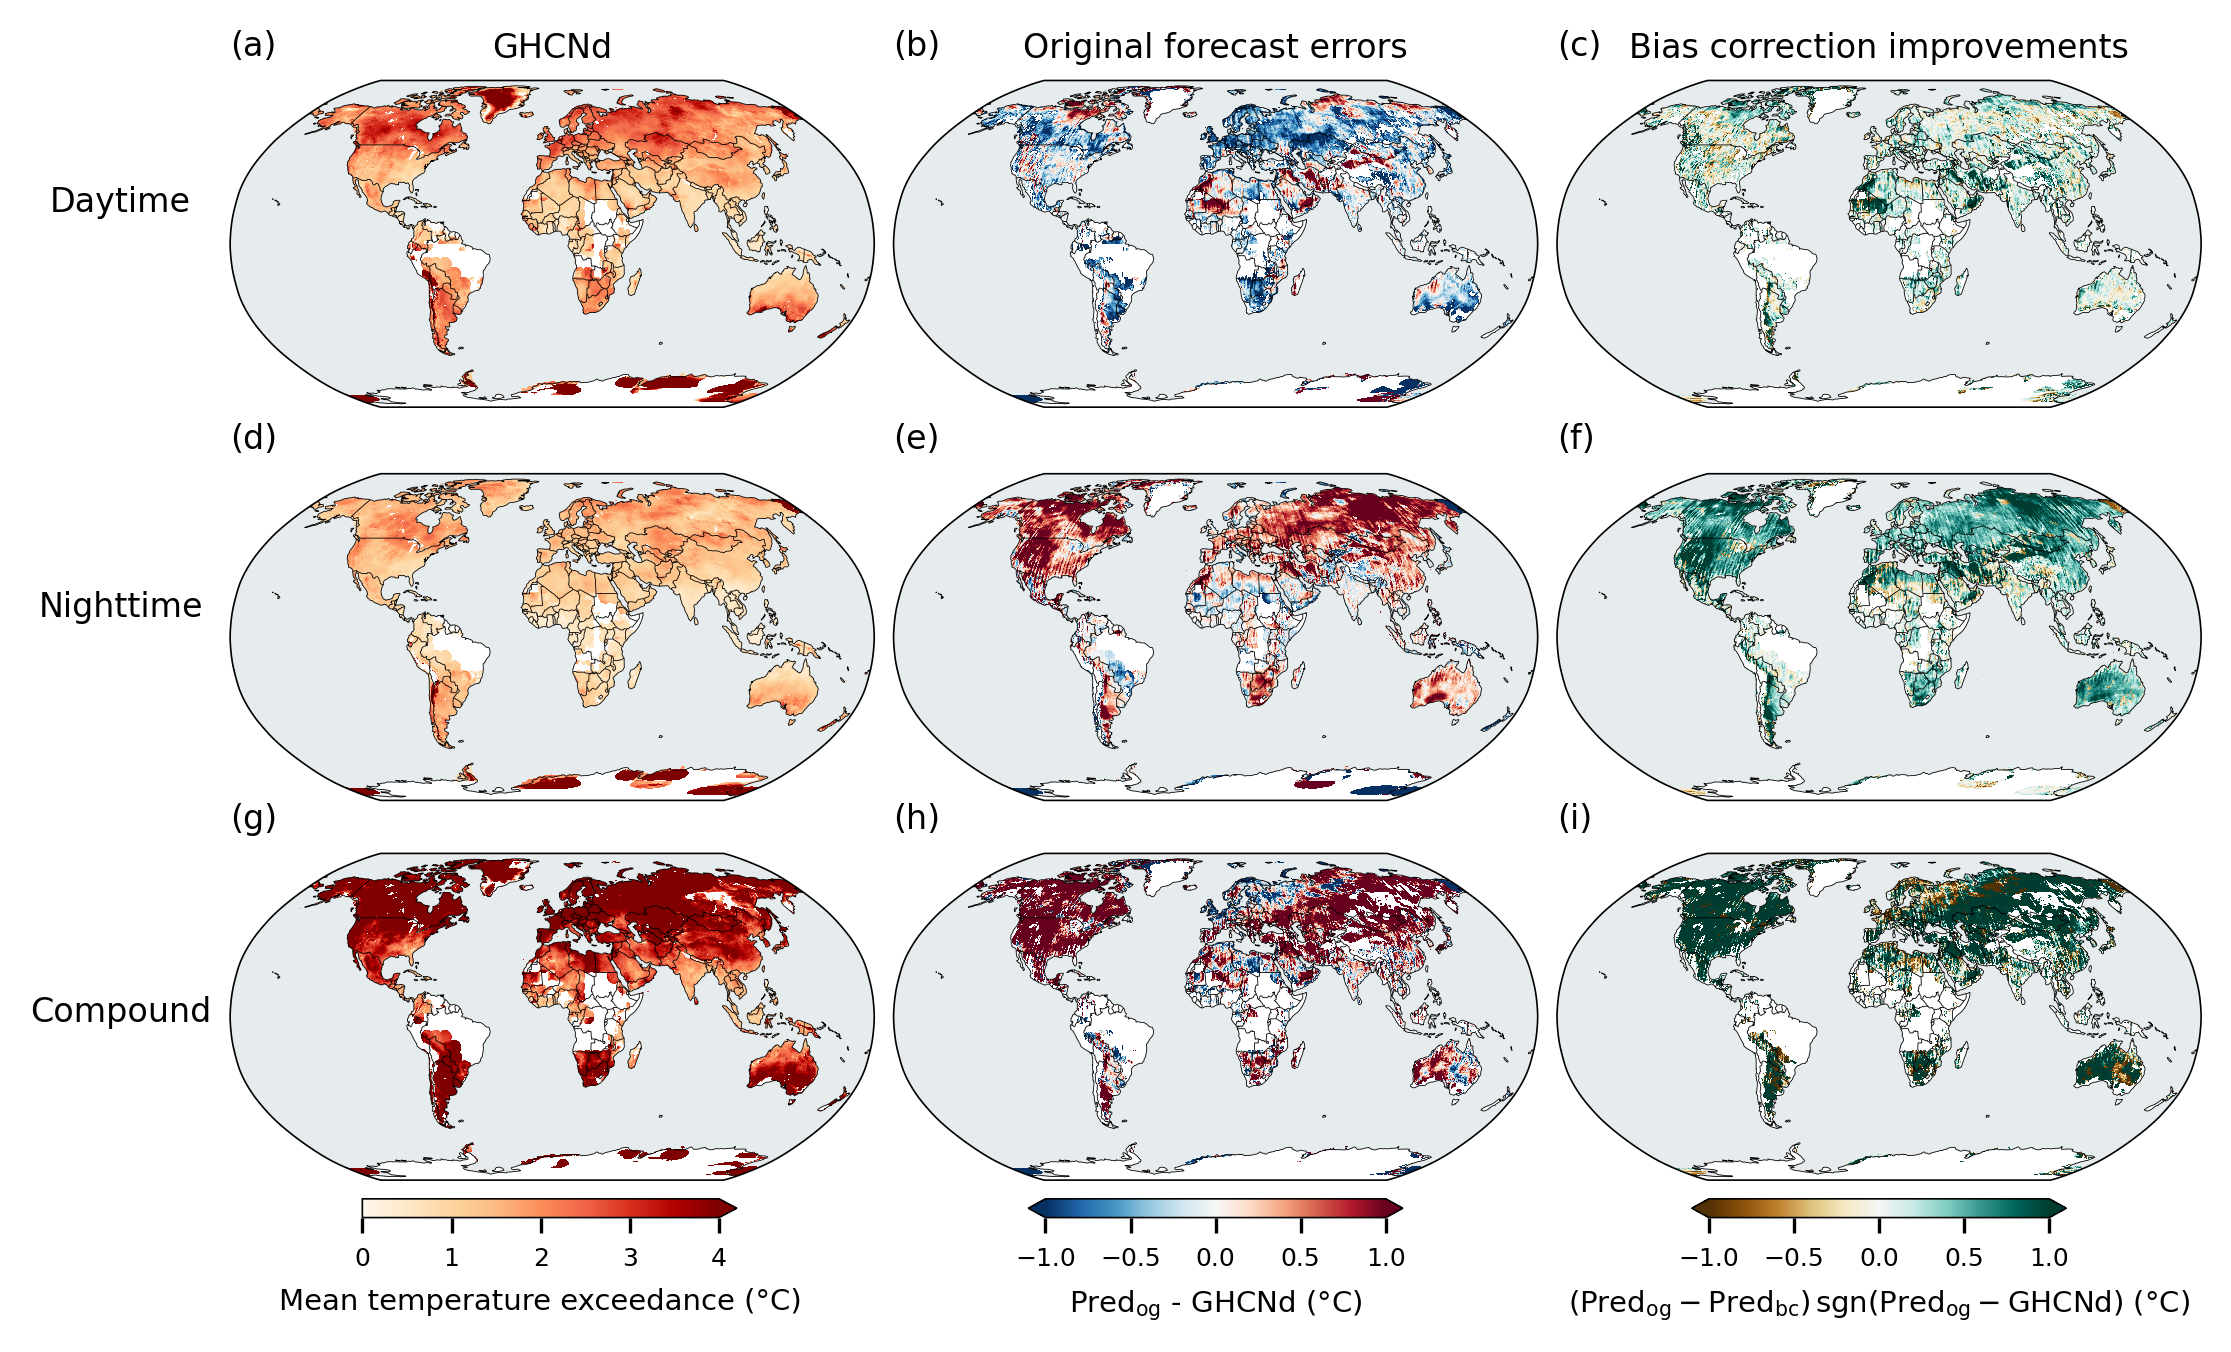

In [10]:
lon2d, lat2d = np.meshgrid(lon_era, lat_era)


fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(7.3, 4.5), dpi=300, 
                         constrained_layout=False, subplot_kw={'projection': ccrs.Robinson()})
plt.subplots_adjust(left=0.08, right=0.98, top=0.92, bottom=0.06, wspace=0.03, hspace=0.05)

ocean =  cfeature.OCEAN.with_scale("110m")

# add super titles
fig.text(0.03, 0.8, "Daytime", ha="center", va="bottom", fontsize=8)
fig.text(0.03, 0.5, "Nighttime", ha="center", va="bottom", fontsize=8)
fig.text(0.03, 0.2, "Compound", ha="center", va="bottom", fontsize=8)

axes[0,0].text(0.5, 1.1, 'GHCNd', transform=axes[0,0].transAxes,
                rotation=0, ha="center", va="center", fontsize=8,)
axes[0,1].text(0.5, 1.1, "Original forecast errors", transform=axes[0,1].transAxes,
                rotation=0, ha="center", va="center", fontsize=8,)
axes[0,2].text(0.5, 1.1, "Bias correction improvements", transform=axes[0,2].transAxes,
                rotation=0, ha="center", va="center", fontsize=8,)

for ax in axes[0,:]:
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

for ax in axes[1,:]:
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)

for ax in axes[2,:]:
    for spine in ax.spines.values():
        spine.set_linewidth(0.4)


axes[0,0].set_title("(a)", loc='left', fontsize=8, fontweight='normal')
axes[0,0].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
axes[0,0].pcolormesh(lon2d, lat2d, heatave_day_obs, cmap='OrRd', shading='auto', vmin=0, vmax=4, transform=ccrs.PlateCarree())
axes[0,0].coastlines(linewidth=0.2)
axes[0,0].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[0,1].set_title("(b)", loc='left', fontsize=8, fontweight='normal')
axes[0,1].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
axes[0,1].pcolormesh(lon2d, lat2d, heatave_day_og - heatave_day_obs, cmap='RdBu_r', shading='auto', vmin=-1, vmax=1, transform=ccrs.PlateCarree())
axes[0,1].coastlines(linewidth=0.2)
axes[0,1].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[0,2].set_title("(c)", loc='left', fontsize=8, fontweight='normal')
axes[0,2].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
axes[0,2].pcolormesh(lon2d, lat2d, (-(heatave_day_bc - heatave_day_og)*(heatave_day_og - heatave_day_obs))/abs(heatave_day_og - heatave_day_obs), cmap='BrBG', shading='auto', vmin=-1, vmax=1, transform=ccrs.PlateCarree())
axes[0,2].coastlines(linewidth=0.2)
axes[0,2].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[1,0].set_title("(d)", loc='left', fontsize=8, fontweight='normal')
axes[1,0].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
axes[1,0].pcolormesh(lon2d, lat2d, heatave_night_obs, cmap='OrRd', shading='auto', vmin=0, vmax=4, transform=ccrs.PlateCarree())
axes[1,0].coastlines(linewidth=0.2)
axes[1,0].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[1,1].set_title("(e)", loc='left', fontsize=8, fontweight='normal')
axes[1,1].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
axes[1,1].pcolormesh(lon2d, lat2d, heatave_night_og - heatave_night_obs, cmap='RdBu_r', shading='auto', vmin=-1, vmax=1, transform=ccrs.PlateCarree())
axes[1,1].coastlines(linewidth=0.2)
axes[1,1].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[1,2].set_title("(f)", loc='left', fontsize=8, fontweight='normal')
axes[1,2].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
axes[1,2].pcolormesh(lon2d, lat2d, (-(heatave_night_bc - heatave_night_og)*(heatave_night_og - heatave_night_obs))/abs(heatave_night_og - heatave_night_obs), cmap='BrBG', shading='auto', vmin=-1, vmax=1, transform=ccrs.PlateCarree())
axes[1,2].coastlines(linewidth=0.2)
axes[1,2].add_feature(cfeature.BORDERS, linewidth=0.2)

axes[2,0].set_title("(g)", loc='left', fontsize=8, fontweight='normal')
axes[2,0].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im1 = axes[2,0].pcolormesh(lon2d, lat2d, heatave_comp_obs, cmap='OrRd', shading='auto', vmin=0, vmax=4, transform=ccrs.PlateCarree())
axes[2,0].coastlines(linewidth=0.2)
axes[2,0].add_feature(cfeature.BORDERS, linewidth=0.2)
cbar1 = plt.colorbar(im1, ax=axes[2,0], fraction=0.05, shrink=0.75, extend='max', pad=0.05, ticks=np.arange(0, 5, 1), orientation="horizontal")
cbar1.ax.tick_params(labelsize=6)
cbar1.set_label('Mean temperature exceedance (°C)', fontsize=7)
cbar1.outline.set_linewidth(0.4)

axes[2,1].set_title("(h)", loc='left', fontsize=8, fontweight='normal')
axes[2,1].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im2 = axes[2,1].pcolormesh(lon2d, lat2d, heatave_comp_og - heatave_comp_obs, cmap='RdBu_r', shading='auto', vmin=-1, vmax=1, transform=ccrs.PlateCarree())
axes[2,1].coastlines(linewidth=0.2)
axes[2,1].add_feature(cfeature.BORDERS, linewidth=0.2)
cbar2 = plt.colorbar(im2, ax=axes[2,1], fraction=0.05, shrink=0.75, extend='both', pad=0.05, ticks=np.arange(-1, 1.5, 0.5), orientation="horizontal")
cbar2.ax.tick_params(labelsize=6)
cbar2.set_label(r"$\mathrm{Pred}_{\mathrm{og}}$ - GHCNd (°C)", fontsize=7)
cbar2.outline.set_linewidth(0.4)

axes[2,2].set_title("(i)", loc='left', fontsize=8, fontweight='normal')
axes[2,2].add_feature(ocean, facecolor="#DCE3E6", edgecolor="none", alpha=0.7,zorder=0)
im3 = axes[2,2].pcolormesh(lon2d, lat2d, (-(heatave_comp_bc - heatave_comp_og)*(heatave_comp_og - heatave_comp_obs))/abs(heatave_comp_og - heatave_comp_obs), cmap='BrBG', shading='auto', vmin=-1, vmax=1, transform=ccrs.PlateCarree())
axes[2,2].coastlines(linewidth=0.2)
axes[2,2].add_feature(cfeature.BORDERS, linewidth=0.2)
cbar3 = plt.colorbar(im3, ax=axes[2,2], fraction=0.05, shrink=0.75, extend='both', pad=0.05, ticks=np.arange(-1, 1.5, 0.5), orientation="horizontal")
cbar3.ax.tick_params(labelsize=6)
cbar3.set_label(r'$(\mathrm{Pred}_{\mathrm{og}}-\mathrm{Pred}_{\mathrm{bc}})\,\mathrm{sgn}(\mathrm{Pred}_{\mathrm{og}}-\mathrm{GHCNd})$ (°C)', fontsize=7)
cbar3.outline.set_linewidth(0.4)